# CS-6600 Project Part 1 - Exploratory Data Analysis

*Weber State University*

**Your Team**: YOUR TEAM NAME AND NAMES OF TEAM MEMBERS HERE : Jeffery Hatch, Fred Walter, Issac Christensen

Your analysis should be below. Unlike previous assignments, there's not a lot of scaffolding provided for you. It's mostly up to you.

## Three questions
1. Can we identify the authoring LLM when evaluating responses to prompts not included in the training.
2.
3.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import re
import nltk
import string
import unicodedata

nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.tokenize import sent_tokenize

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Fred\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Fred\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [2]:
url = "https://raw.githubusercontent.com/FredWltr/NameThatLLM/refs/heads/main/dataset/data.csv"

data = pd.read_csv(url)
data.head()

,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


In [3]:
print("Number of rows:", len(data))

print("Columns:", data.columns.tolist())

display(data.head())

print("\nFirst paragraph:")
print(data.loc[0, "text"])

print("\nModel that wrote it:")
print(data.loc[0, "model"])

Number of rows: 2699
Columns: ['id', 'prompt_id', 'text', 'model']


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash



First paragraph:
When a language dies, a particular astronomy dims: not only names for stars, but whole grammars of attention that taught speakers how to read the night. Some tongues map the sky by kinship, binding the Milky Way to ancestors, rivers, or the migration paths of birds; others encode lunar phases as verbs, so time is not a line but a recurring breath. A word can carry the exact color of dawn on snow, the etiquette of speaking to thunder, or the mathematics woven into knot calendars and oral star charts. With extinction, those relations collapse into silence. No dictionary can resurrect the sky those speakers inhabited, nor the quiet ethics it taught. We lose metaphors that made the universe intimate, ethical, and alive, cosmologies in which darkness is a listener, comets are warnings carried by relatives, and constellations are not fixed pictures but seasonal responsibilities. The loss is not merely lexical; it is the erasure of possible human answers to wonder. What rema

In [4]:
# Looking at how many samples per model and for any missing data or duplicate data
print("Missing values in each column:")
display(data.isna().sum().to_frame("missing_count"))

print("\nNumber of different prompts:")
print(data["prompt_id"].nunique())

print("\nNumber of different LLMs:")
print(data["model"].nunique())

print("\nParagraphs written by each LLM:")
display(data["model"].value_counts().to_frame("paragraph_count"))

print("\nNumber of repeated identical paragraphs:")
print(data["text"].duplicated().sum())

Missing values in each column:


,missing_count
id,0
prompt_id,0
text,0
model,0



Number of different prompts:
150

Number of different LLMs:
18

Paragraphs written by each LLM:


,paragraph_count
model,
qwen3.8-max,150
claude-sonnet-5,150
gemini-3.6-flash,150
gpt-5.6-terra,150
glm-5.3-flash,150
gemini-3.1-pro-preview,150
gemini-3.8-flash,150
claude-opus-4-6,150
gpt-5.6-luna,150



Number of repeated identical paragraphs:
0


,min,median,mean,max
model,,,,
claude-fable-5,39,100.0,112.5,252
claude-opus-4-6,42,98.5,115.1,274
claude-opus-4-8,42,109.0,123.6,251
claude-opus-5,39,116.5,123.4,257
claude-sonnet-5,39,99.5,120.0,267
gemini-3.1-pro-preview,38,104.0,119.3,262
gemini-3.6-flash,40,95.5,111.2,238
gemini-3.7-flash,40,101.5,117.1,252
gemini-3.8-flash,41,84.0,100.7,238


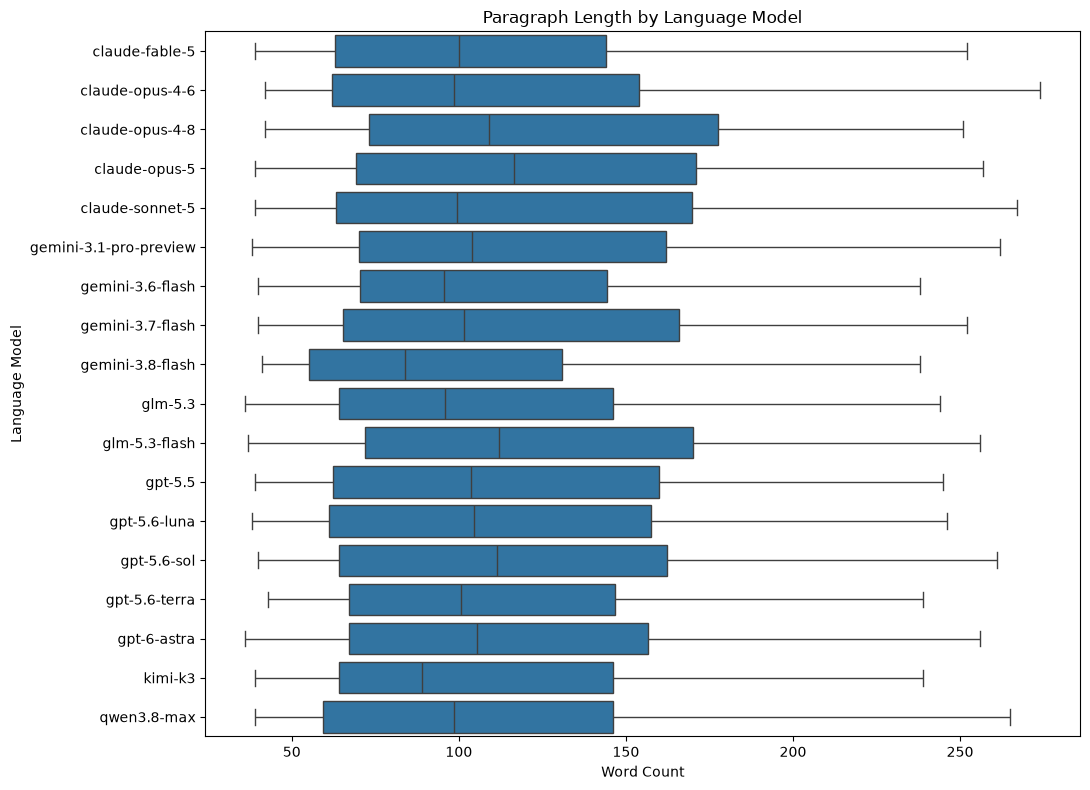

In [5]:
exploration = data.copy()
exploration["word_count"] = (exploration["text"].str.split().str.len())

display(exploration.groupby("model")["word_count"].agg(["min", "median", "mean", "max"]).round(1))

plt.figure(figsize=(11, 8))

sns.boxplot(data=exploration,x="word_count",y="model",order=sorted(exploration["model"].unique()))
plt.title("Paragraph Length by Language Model")
plt.xlabel("Word Count")
plt.ylabel("Language Model")
plt.tight_layout()
plt.show()

In [6]:
data["word_count"] = (data["text"].str.split().str.len())

In [7]:
def average_word_length(text):
    words = re.findall(r'\b[A-Za-z]+\b', str(text))
    return sum(len(word) for word in words) / len(words) if words else 0

data['avg_word_length'] = data['text'].fillna('').apply(average_word_length)

In [8]:
def average_sentence_length(text):
    sentences = sent_tokenize(str(text))

    if not sentences:
        return 0

    word_count = sum(
        len(sentence.split())
        for sentence in sentences
    )

    return word_count / len(sentences)

data['avg_sentence_length'] = data['text'].fillna('').apply(
    average_sentence_length
)

In [9]:
data['sentence_count'] = data['text'].fillna('').apply(
    lambda x: len(sent_tokenize(x))
)

In [10]:
data['punctuation_count'] = data['text'].fillna('').apply(
    lambda x: sum(1 for char in str(x) if char in string.punctuation)
)

In [11]:
def count_symbols(text):
    return sum(
        1 for char in str(text)
        if unicodedata.category(char)[0] == 'S'
    )

data['symbol_count'] = data['text'].fillna('').apply(count_symbols)

In [12]:
# Combine all text into one string
all_text = data['text'].fillna('').astype(str).str.cat(sep='')

# Keep only punctuation marks that appear at least once
punctuation_list = [
    p for p in string.punctuation
    if p in all_text
]

print("Punctuation found:", punctuation_list)
print("Number of punctuation types:", len(punctuation_list))

Punctuation found: ['!', '"', '$', "'", '(', ')', '*', '+', ',', '-', '.', '/', ':', ';', '<', '=', '>', '?', '[', '\\', ']', '^', '_', '{', '}']
Number of punctuation types: 25


In [13]:
for p in punctuation_list:
    count = data['text'].fillna('').apply(
        lambda x: str(x).count(p)
    )

    data[f'ratio_{p}'] = (count / data['punctuation_count'])
    

In [14]:
data

,id,prompt_id,text,model,word_count,avg_word_length,avg_sentence_length,sentence_count,punctuation_count,symbol_count,...,ratio_=,ratio_>,ratio_?,ratio_[,ratio_\,ratio_],ratio_^,ratio__,ratio_{,ratio_}
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max,192,4.782383,24.000000,8,28,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5,65,6.611940,16.250000,4,11,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash,77,5.012987,19.250000,4,12,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra,220,6.576577,24.444444,9,45,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash,97,4.343434,24.250000,4,13,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2694,ff4344ceda23,p075,"Across centuries of silence and shadow, an inv...",gemini-3.8-flash,156,5.668790,26.000000,6,20,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2695,ff507658ba82,p092,Though both instruments breathe the exact same...,gemini-3.7-flash,74,6.094595,18.500000,4,12,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2696,ff50c252810c,p113,A single photon leaves the star as neither wav...,claude-opus-4-8,83,4.506024,20.750000,4,12,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2697,ffcf6321f7e9,p073,Data science communities matter because they t...,glm-5.3,83,6.929412,16.600000,5,17,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Observations:

